In [20]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

In [2]:
df = pd.read_csv("../data/processed/documents_raw.csv")
# df = df[~df.is_legal_page]
# df = df[['doc_id', 'title', 'text']]

In [3]:
df.head()

,id,source,lang,title,text,domain,content_hash
0,a677b8799f7717173debe8cc16740246f8b38561,picture_perfect_portfolios,en,How I Invest with Trending Value: 100% Factor ...,As an amateur investor I'm often torn between ...,PicturePerfectPortfolios.com,ed983165516b3617d7abd4cad187d5bdf65abd56
1,8ac2d21c3b41b41b77a21749e77e5aa7be0d99fe,picture_perfect_portfolios,en,10 Compelling Reasons to Choose a Growth Inves...,Investing in growth stocks has become increasi...,PicturePerfectPortfolios.com,7d5a2f25e1453bf62a09d7a3f662fa385c6ea3b1
2,6fbd980455504303e0a89b4b10706bfe287d0c25,picture_perfect_portfolios,en,10 Lessons Learned from Past Housing Bubbles a...,A housing bubble occurs when the prices of hom...,PicturePerfectPortfolios.com,38ce27ae84d85c43f7dae49453360869a0a623d4
3,0436575965a2ef9df4b286362a84085f0a6d7c1d,picture_perfect_portfolios,en,10 Things Investors Need To Know About Managed...,No other investing strategy has enjoyed a grea...,PicturePerfectPortfolios.com,a73d772055c2826a6be48e7133eb5cb74c81c13f
4,533199aaa9e9f030931f713cd285833248fcf818,picture_perfect_portfolios,en,10 Ways Investors Can Improve A 60/40 Portfoli...,The 60/40 portfolio is by and large considered...,PicturePerfectPortfolios.com,a4c904805ff9e57e995653fd9413a4a500e66ce8


## Chunking pipeline

Input: `documents_raw.csv`, the JSON fields copied exactly. Chunking runs directly on the raw `text` column, with **no cleaning or noise removal**. This section builds two chunk sets to compare later in retrieval experiments:

| Strategy | Boundaries | FAQ handling | Text that gets embedded |
|---|---|---|---|
| **A: fixed-size baseline** | Every `MAX_TOKENS` with `OVERLAP_TOKENS` stride, ignoring structure | None (Q&A pairs get cut through) | The chunk text |
| **B: structure-aware** | Heading-delimited sections, then token windows that snap to paragraph/sentence boundaries and never cross a section | Detected inside the raw text; **one chunk per Q&A pair**, `chunk_type="faq"` | `"{title} › {section}\n{text}"` |

Steps: tokenizer → load raw docs → line classifiers → FAQ extraction → body sectioning & windowing → build A and B → diagnostics → save.

In [4]:
EMBEDDING_MODEL = "sentence-transformers/all-mpnet-base-v2"  # placeholder until the embedding model is chosen
TARGET_MAX_TOKENS = 350  # desired chunk budget; capped to fit the model's window in the tokenizer cell
HEADER_RESERVE = 64  # room for the "{title} › {section}" header prepended to embed_text
OVERLAP_TOKENS = 50  # context carried into the next window
MIN_SECTION_TOKENS = 50  # smaller sections are folded into the following one
OUT_DIR = "../data/processed"

### 1. Tokenizer

Chunk sizes are measured with the **embedding model's own tokenizer**, so the budget matches what the model actually reads. The chunk budget is `TARGET_MAX_TOKENS`, capped so that a chunk plus its header and the model's special tokens fits inside `max_seq_length` (512 for bge, 384 for all-mpnet-base-v2, 256 for all-MiniLM). Change `EMBEDDING_MODEL` and **Restart & Run All**. If the model can't be loaded (offline), token counts fall back to a word-count approximation.

In [5]:
try:
    model = SentenceTransformer(EMBEDDING_MODEL)
    tok = model.tokenizer  # the exact tokenizer the model embeds with
    MAX_SEQ_LENGTH = model.max_seq_length  # 512 for bge, 384 for all-mpnet, 256 for all-MiniLM; longer inputs get truncated

    def n_tokens(text: str) -> int:
        # verbose=False silences the "longer than max sequence length" warning; we're only counting here
        return len(tok(text, add_special_tokens=False, verbose=False)["input_ids"])

except Exception as e:  # offline / model not downloadable
    print(f"Model unavailable ({e}); falling back to ~1.3 tokens per word")
    model, tok, MAX_SEQ_LENGTH = None, None, 512

    def n_tokens(text: str) -> int:
        return int(len(text.split()) * 1.3)


# Chunk budget must leave room for the header and the model's special tokens, or the tail gets truncated
MAX_TOKENS = min(TARGET_MAX_TOKENS, MAX_SEQ_LENGTH - HEADER_RESERVE - 2)
OVERLAP_TOKENS = min(OVERLAP_TOKENS, MAX_TOKENS // 4)
print(f"{EMBEDDING_MODEL}: max_seq_length={MAX_SEQ_LENGTH} -> MAX_TOKENS={MAX_TOKENS}, OVERLAP_TOKENS={OVERLAP_TOKENS}")
n_tokens("The classic All Weather portfolio holds 40% long-term Treasuries.")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7731.47it/s]


sentence-transformers/all-mpnet-base-v2: max_seq_length=384 -> MAX_TOKENS=318, OVERLAP_TOKENS=50


16

### 2. Load raw documents

Each document's `text` is used exactly as it appears in `documents_raw.csv`. Only `id` is renamed to `doc_id` for clarity.

In [6]:
docs = df.rename(columns={"id": "doc_id"})[["doc_id", "title", "text"]].copy()
print(f"{len(docs)} docs | {docs.text.str.len().sum():,} chars | median {docs.text.str.len().median():,.0f} chars/doc")

448 docs | 16,262,910 chars | median 35,140 chars/doc


### 2b. Line classifiers

The raw text has no markup, so its structure is inferred line by line:
- **heading**: short, doesn't end like a sentence, and isn't a `source:` caption, URL or bullet
- **FAQ heading**: a heading that mentions "FAQ"
- **question**: any line ending in `?`, numbered or not

In [7]:
FAQ_HEADING_RE = re.compile(r"^.{0,200}\bFAQs?\b.{0,200}(?<![.!])$")  # "12-Question FAQ — …", not "No. This FAQ is …."
# A question is any line ending in "?" (numbered or not). Requiring the "?" stops numbered
# non-questions such as "1. Educational Purpose, …" counting as questions.
FAQ_QUESTION_RE = re.compile(r"^.+\?$")
GLUED_QA_RE = re.compile(r"\?(?=[A-Z])")  # "…in one sentence?An exchange-traded fund…"
TERMINAL_PUNCT = tuple(".!?:;,…\"'”’)]")


def is_heading(line: str, max_chars: int = 80, max_words: int = 12) -> bool:
    """Short line that doesn't end like a sentence and isn't a caption, URL or bullet."""
    s = line.strip()
    return (
        0 < len(s) <= max_chars
        and len(s.split()) <= max_words
        and not s.endswith(TERMINAL_PUNCT)
        and not s.lower().startswith(("source:", "http", "www."))
        and not s.startswith(("-", "•", "*"))
    )


def is_question(line: str) -> bool:
    return bool(FAQ_QUESTION_RE.match(line.strip()))


for s in ["Ray Dalio All Weather Portfolio Allocations", "1) What is the classic All Weather Portfolio?",
          "source: portfoliovisualizer.com", "Please let me know in the comments below.",
          "1. Educational Purpose, Publisher’s Exclusion & No Solicitation"]:
    print(f"heading={is_heading(s)!s:5}  question={is_question(s)!s:5}  {s}")

heading=True   question=False  Ray Dalio All Weather Portfolio Allocations
heading=False  question=True   1) What is the classic All Weather Portfolio?
heading=False  question=False  source: portfoliovisualizer.com
heading=False  question=False  Please let me know in the comments below.
heading=True   question=False  1. Educational Purpose, Publisher’s Exclusion & No Solicitation


### 3. Extract the FAQ from the raw text

There's no FAQ field in the JSON, so it's found from the text structure:

- **Start**: the *last* FAQ-style heading after the first 40% of the document. This skips "FAQ" mentions in the intro.
- **Questions**: lines ending in `?`. Text where a question runs straight into its answer (`…sentence?An ETF…`) is split apart first.
- **End**: the FAQ is often *not* the end of the document. Closing sections ("Final Thoughts", "Conclusion", "Connect With …") and the site footer frequently follow it. The FAQ ends at the first heading after the last question's answer, and everything after that becomes **post-FAQ** text, chunked as ordinary body content.

Trade-off: a bullet list inside the *last* answer can be cut off and moved to post-FAQ. It still gets indexed, just labelled as body.

In [8]:
FAQ_MIN_POSITION = 0.4  # the FAQ heading must sit in the latter 60% of the document


def split_faq(text: str) -> tuple[str, str, str, str]:
    """Return (body, faq_heading, faq, post_faq). Empty strings when no FAQ is found."""
    lines = text.split("\n")

    # 1. FAQ start = last FAQ-style heading past FAQ_MIN_POSITION
    offset, start = 0, None
    for i, line in enumerate(lines):
        if FAQ_HEADING_RE.match(line.strip()) and offset >= FAQ_MIN_POSITION * len(text):
            start = i
        offset += len(line) + 1
    if start is None:
        return text, "", "", ""

    heading = lines[start].strip()
    rest = []
    for line in lines[start + 1:]:
        rest.extend(GLUED_QA_RE.sub("?\n", line).split("\n"))
    q_idx = [i for i, line in enumerate(rest) if is_question(line)]
    if not q_idx:
        return text, "", "", ""

    # 2. FAQ end = first heading after the last question's first answer line
    end = len(rest)
    for j in range(q_idx[-1] + 2, len(rest)):
        if is_heading(rest[j]):
            end = j
            break

    body = "\n".join(lines[:start]).strip()
    faq = "\n".join(rest[:end]).strip()
    post = "\n".join(rest[end:]).strip()
    return body, heading, faq, post


def split_qa_pairs(faq: str) -> list[tuple[str, str]]:
    """Group FAQ lines into (question, answer); an answer is every line until the next question."""
    pairs, question, answer = [], None, []
    for line in (l.strip() for l in faq.split("\n") if l.strip()):
        if is_question(line):
            if question and answer:
                pairs.append((question, "\n".join(answer)))
            question, answer = line, []
        elif question:
            answer.append(line)
    if question and answer:
        pairs.append((question, "\n".join(answer)))
    return pairs

In [9]:
faq_parts = docs["text"].map(split_faq)
docs["has_faq"] = faq_parts.map(lambda p: bool(p[2]))
docs["faq_pairs"] = faq_parts.map(lambda p: len(split_qa_pairs(p[2])))
docs["has_post_faq"] = faq_parts.map(lambda p: bool(p[3]))

print(f"docs with FAQ:        {docs.has_faq.sum()} / {len(docs)}")
print(f"FAQ followed by text: {docs.has_post_faq.sum()} (Final Thoughts / Conclusion / Connect With / footer …)")
print("Q&A pairs per FAQ:   ", docs.loc[docs.has_faq, "faq_pairs"].describe()[["min", "50%", "max"]].to_dict())

# Walk through one article
sample = docs.loc[docs.title.str.startswith("10 Ways Investors Can Improve The Ray Dalio"), "text"].iloc[0]
body, faq_heading, faq, post = split_faq(sample)
print(f"\nbody {len(body):,} chars | FAQ '{faq_heading}' {len(faq):,} chars | post-FAQ {len(post):,} chars")
for q, a in split_qa_pairs(faq)[:2]:
    print(f"\nQ: {q}\nA: {a[:200]}")

docs with FAQ:        393 / 448
FAQ followed by text: 393 (Final Thoughts / Conclusion / Connect With / footer …)
Q&A pairs per FAQ:    {'min': 10.0, '50%': 12.0, 'max': 16.0}

body 22,402 chars | FAQ '12-Question FAQ — 10 Ways Investors Can Improve the Ray Dalio All Weather Portfolio' 2,926 chars | post-FAQ 7,627 chars

Q: 1) What is the classic Ray Dalio All Weather Portfolio?
A: A rules-driven allocation aimed to work across economic regimes: 30% US stocks, 40% long-term Treasuries, 15% intermediate Treasuries, 7.5% gold, 7.5% commodities—tilting conservative vs. a 60/40 whil

Q: 2) Why try to “improve” an All Weather portfolio?
A: To maintain the all-regime intent while pursuing higher risk-adjusted returns and shallower drawdowns by expanding beyond long-only stocks/bonds/commodities and adding uncorrelated strategies.


### 4. Body sections and token windows

1. **Sections**: split at heading-like lines. Text before the first heading becomes `Introduction`.
2. **Merge small sections**: any section under `MIN_SECTION_TOKENS` (a heading followed by a one-line caption, for example) is folded into the next one, so you don't get tiny chunks with no context.
3. **Units**: paragraphs (lines). A paragraph over the budget is split into sentences, and a sentence still over budget is cut at token boundaries.
4. **Window**: units are packed greedily up to `MAX_TOKENS`. The next chunk starts with the trailing units of the previous one, up to `OVERLAP_TOKENS`. Windows never cross a section boundary.

In [10]:
def split_sections(text: str, default: str = "Introduction") -> list[tuple[str, str]]:
    """Split text into (heading, content) pairs at heading-like lines."""
    sections, heading, buf = [], default, []
    for line in text.split("\n"):
        if not line.strip():
            continue
        if is_heading(line):
            if buf:
                sections.append((heading, "\n".join(buf)))
            heading, buf = line.strip(), []
        else:
            buf.append(line.strip())
    if buf:
        sections.append((heading, "\n".join(buf)))
    return sections


def merge_small_sections(sections, min_tokens: int = MIN_SECTION_TOKENS):
    """Fold sections under `min_tokens` into the next one, keeping the absorbed heading as a line."""
    merged, carry = [], None
    for heading, body in sections:
        if carry:
            heading, body = carry[0], f"{carry[1]}\n{heading}\n{body}"
            carry = None
        if n_tokens(body) < min_tokens:
            carry = (heading, body)
        else:
            merged.append((heading, body))
    if carry:
        if merged:
            h, b = merged[-1]
            merged[-1] = (h, f"{b}\n{carry[0]}\n{carry[1]}")
        else:
            merged.append(carry)
    return merged


SENT_RE = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"“(])")


def hard_split(text: str, max_tokens: int) -> list[str]:
    """Last resort for a single sentence/table row over budget: cut on token offsets."""
    if tok is None:
        words, step = text.split(), int(max_tokens / 1.3)
        return [" ".join(words[i:i + step]) for i in range(0, len(words), step)]
    offs = tok(text, add_special_tokens=False, return_offsets_mapping=True, verbose=False)["offset_mapping"]
    return [text[offs[i][0]:offs[min(i + max_tokens, len(offs)) - 1][1]] for i in range(0, len(offs), max_tokens)]


def to_units(text: str, max_tokens: int) -> list[str]:
    """Paragraphs, falling back to sentences, then hard token cuts, so every unit fits the budget."""
    units = []
    for para in text.split("\n"):
        if not para.strip():
            continue
        if n_tokens(para) <= max_tokens:
            units.append(para)
            continue
        for sent in SENT_RE.split(para):
            units.extend([sent] if n_tokens(sent) <= max_tokens else hard_split(sent, max_tokens))
    return units


def window(text: str, max_tokens: int = MAX_TOKENS, overlap: int = OVERLAP_TOKENS) -> list[str]:
    """Greedy-pack units up to `max_tokens`; start each next chunk with trailing units worth <= `overlap` tokens."""
    units = to_units(text, max_tokens)
    sizes = [n_tokens(u) for u in units]
    chunks, cur, cur_sizes = [], [], []
    for unit, size in zip(units, sizes):
        if cur and sum(cur_sizes) + size > max_tokens:
            chunks.append("\n".join(cur))
            k = len(cur)
            while k > 0 and sum(cur_sizes[k - 1:]) <= overlap:
                k -= 1
            cur, cur_sizes = cur[k:], cur_sizes[k:]
            if cur and sum(cur_sizes) + size > max_tokens:  # overlap + next unit won't fit
                cur, cur_sizes = [], []
        cur.append(unit)
        cur_sizes.append(size)
    if cur:
        chunks.append("\n".join(cur))
    return chunks


demo_body = split_faq(sample)[0]
for heading, sec in merge_small_sections(split_sections(demo_body))[:6]:
    print(f"[{n_tokens(sec):4d} tok → {len(window(sec))} chunk(s)] {heading}")

[ 276 tok → 1 chunk(s)] Introduction
[  94 tok → 1 chunk(s)] About the Author & Disclosure
[ 228 tok → 1 chunk(s)] 10 Ways to Improve the Ray Dalio All Weather Portfolio
[ 294 tok → 1 chunk(s)] Ray Dalio All Weather Portfolio Allocations
[ 262 tok → 1 chunk(s)] 1) Add Global Equities To The All-Weather Portfolio
[ 317 tok → 1 chunk(s)] 2) Minimum Volatility Equities Upgrade To The All-Weather Portfolio


### 5. Strategy B: structure-aware chunks

For each article, in document order:
- **body**: sections, then token windows
- **faq**: one chunk per Q&A pair. Engagement prompts ("let me know in the comments") are dropped, and an oversized answer is split, with each piece keeping its question
- **post-FAQ**: closing sections, then token windows, labelled `body`

Each chunk stores the raw `text` (for quoting and citation checks) and an `embed_text` with a `title › section` header (for the vector index).

In [11]:
# Engagement prompts ("Which is your favourite? Let me know in the comments below.") carry no facts
ENGAGEMENT_RE = re.compile(r"let me know in the comment", re.I)


def chunk_doc_structured(doc) -> list[dict]:
    body, faq_heading, faq, post = split_faq(doc.text)
    out = []

    def add(section: str, chunk_type: str, text: str, question: str = "") -> None:
        out.append(dict(section=section, chunk_type=chunk_type, question=question, text=text,
                        embed_text=f"{doc.title} › {section}\n{text}"))

    for title, sec in merge_small_sections(split_sections(body)):
        for c in window(sec):
            add(title, "body", c)

    for q, a in split_qa_pairs(faq):
        if ENGAGEMENT_RE.search(a):
            continue
        budget = MAX_TOKENS - n_tokens(q)
        pieces = [a] if n_tokens(a) <= budget else window(a, max_tokens=budget, overlap=0)
        for piece in pieces:  # oversized answers are split; each piece keeps its question
            add(faq_heading, "faq", f"{q}\n{piece}", question=q)

    for title, sec in merge_small_sections(split_sections(post, default="Closing")):
        for c in window(sec):
            add(title, "body", c)
    return out


def build_chunks(docs: pd.DataFrame, chunk_fn, strategy: str) -> pd.DataFrame:
    rows = []
    for doc in docs.itertuples(index=False):
        for i, c in enumerate(chunk_fn(doc)):
            rows.append({"chunk_id": f"{doc.doc_id}:{strategy}:{i:04d}", "doc_id": doc.doc_id,
                         "title": doc.title, "chunk_index": i, **c})
    out = pd.DataFrame(rows)
    out["n_tokens"] = out["text"].map(n_tokens)
    return out


chunks_B = build_chunks(docs, chunk_doc_structured, "B")
chunks_B.head(3)

,chunk_id,doc_id,title,chunk_index,section,chunk_type,question,text,embed_text,n_tokens
0,a677b8799f7717173debe8cc16740246f8b38561:B:0000,a677b8799f7717173debe8cc16740246f8b38561,How I Invest with Trending Value: 100% Factor ...,0,Introduction,body,,As an amateur investor I'm often torn between ...,How I Invest with Trending Value: 100% Factor ...,224
1,a677b8799f7717173debe8cc16740246f8b38561:B:0001,a677b8799f7717173debe8cc16740246f8b38561,How I Invest with Trending Value: 100% Factor ...,1,About the Author & Disclosure,body,,Picture Perfect Portfolios is the quantitative...,How I Invest with Trending Value: 100% Factor ...,170
2,a677b8799f7717173debe8cc16740246f8b38561:B:0002,a677b8799f7717173debe8cc16740246f8b38561,How I Invest with Trending Value: 100% Factor ...,2,An Investing Journey: From Boglehead To AQR,body,,Who were your greatest influences as an invest...,How I Invest with Trending Value: 100% Factor ...,282


### 6. Strategy A: fixed-size baseline

A sliding token window over the same raw text, so the A vs B comparison isolates the chunking strategy. Windows are cut by token offsets and sliced from the original string. Decoding token IDs instead would lowercase the text under uncased models like bge, and the stored text has to stay quotable.

In [12]:
def chunk_doc_fixed(doc, max_tokens: int = MAX_TOKENS, overlap: int = OVERLAP_TOKENS) -> list[dict]:
    """Slide a token window over the whole raw text; slice by char offsets so text stays verbatim."""
    text, step = doc.text, max_tokens - overlap
    if tok is None:
        words = text.split()
        w_max, w_step = int(max_tokens / 1.3), int(step / 1.3)
        pieces = [" ".join(words[i:i + w_max]) for i in range(0, len(words), w_step)]
    else:
        offs = tok(text, add_special_tokens=False, return_offsets_mapping=True, verbose=False)["offset_mapping"]
        pieces = []
        for start in range(0, len(offs), step):
            end = min(start + max_tokens, len(offs))
            pieces.append(text[offs[start][0]:offs[end - 1][1]])
            if end == len(offs):
                break
    return [dict(section="", chunk_type="window", question="", text=p, embed_text=p) for p in pieces]


chunks_A = build_chunks(docs, chunk_doc_fixed, "A")
chunks_A.head(3)

,chunk_id,doc_id,title,chunk_index,section,chunk_type,question,text,embed_text,n_tokens
0,a677b8799f7717173debe8cc16740246f8b38561:A:0000,a677b8799f7717173debe8cc16740246f8b38561,How I Invest with Trending Value: 100% Factor ...,0,,window,,As an amateur investor I'm often torn between ...,As an amateur investor I'm often torn between ...,318
1,a677b8799f7717173debe8cc16740246f8b38561:A:0001,a677b8799f7717173debe8cc16740246f8b38561,How I Invest with Trending Value: 100% Factor ...,1,,window,,Europe's Leading Marketing Campaign 2017 & 201...,Europe's Leading Marketing Campaign 2017 & 201...,318
2,a677b8799f7717173debe8cc16740246f8b38561:A:0002,a677b8799f7717173debe8cc16740246f8b38561,How I Invest with Trending Value: 100% Factor ...,2,,window,,"the needle, buy the haystack - and then from t...","the needle, buy the haystack - and then from t...",318


### 7. Diagnostics

In [13]:
for name, c in [("A_fixed", chunks_A), ("B_structured", chunks_B)]:
    print(f"{name:13s} {len(c):6,} chunks | {c.doc_id.nunique()} docs | "
          f"tokens median {c.n_tokens.median():.0f}, max {c.n_tokens.max()}")

# Sanity checks
EMBED_LIMIT = MAX_SEQ_LENGTH - 2  # the model's window minus its special tokens
checks = {
    "A within budget (+5 retokenisation slack)": (chunks_A.n_tokens <= MAX_TOKENS + 5).all(),
    "B within budget": (chunks_B.n_tokens <= MAX_TOKENS).all(),
    "A text fits model window": (chunks_A.embed_text.map(n_tokens) <= EMBED_LIMIT).all(),
    "B embed_text fits model window": (chunks_B.embed_text.map(n_tokens) <= EMBED_LIMIT).all(),
    "no empty chunks": (chunks_A.text.str.strip().ne("").all() and chunks_B.text.str.strip().ne("").all()),
    "unique chunk_ids": chunks_A.chunk_id.is_unique and chunks_B.chunk_id.is_unique,
    "every doc has chunks": chunks_A.doc_id.nunique() == chunks_B.doc_id.nunique() == len(docs),
}
for name, ok in checks.items():
    print(f"{'✓' if ok else '✗'} {name}")

chunks_B.groupby("chunk_type")["n_tokens"].describe()

A_fixed       12,186 chunks | 448 docs | tokens median 318, max 320
B_structured  21,764 chunks | 448 docs | tokens median 129, max 318
✓ A within budget (+5 retokenisation slack)
✓ B within budget
✓ A text fits model window
✓ B embed_text fits model window
✓ no empty chunks
✓ unique chunk_ids
✓ every doc has chunks


,count,mean,std,min,25%,50%,75%,max
chunk_type,,,,,,,,
body,16972.0,164.821765,77.229651,6.0,99.0,157.0,217.0,318.0
faq,4792.0,66.224332,32.227160,6.0,52.0,61.0,71.0,318.0


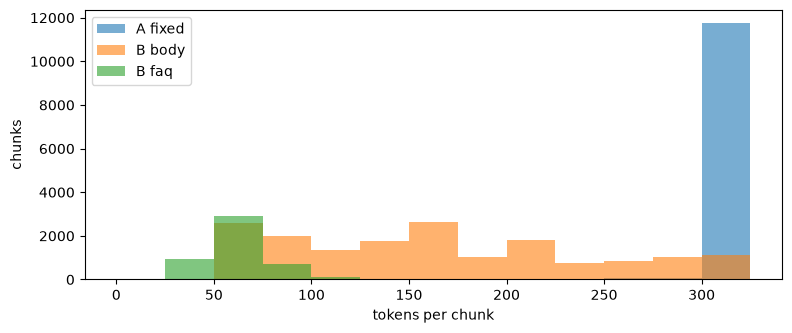

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = range(0, MAX_TOKENS + 26, 25)
ax.hist(chunks_A.n_tokens, bins=bins, alpha=0.6, label="A fixed")
ax.hist(chunks_B[chunks_B.chunk_type == "body"].n_tokens, bins=bins, alpha=0.6, label="B body")
ax.hist(chunks_B[chunks_B.chunk_type == "faq"].n_tokens, bins=bins, alpha=0.6, label="B faq")
ax.set_xlabel("tokens per chunk")
ax.set_ylabel("chunks")
ax.legend()
plt.show()

In [15]:
# Side-by-side look at one article: what the FAQ allocation answer looks like under A vs B
probe = "30% US stocks, 40% long-term Treasuries"
doc_id = chunks_B.loc[chunks_B.text.str.contains(probe, regex=False), "doc_id"].iloc[0]

print("B sections:", chunks_B[chunks_B.doc_id == doc_id].section.drop_duplicates().tolist(), "\n")
print("--- B chunk containing the allocation:\n" + chunks_B[(chunks_B.doc_id == doc_id) & chunks_B.text.str.contains(probe, regex=False)].embed_text.iloc[0], "\n")
print("--- A chunk containing the allocation:\n" + chunks_A[(chunks_A.doc_id == doc_id) & chunks_A.text.str.contains(probe, regex=False)].text.iloc[0])

B sections: ['Introduction', 'About the Author & Disclosure', '10 Ways to Improve the Ray Dalio All Weather Portfolio', 'Ray Dalio All Weather Portfolio Allocations', '1) Add Global Equities To The All-Weather Portfolio', '2) Minimum Volatility Equities Upgrade To The All-Weather Portfolio', '3) Expand The Canvas Of The All-Weather Portfolio', 'Ray Dalio All-Weather Portfolio Performance 100%', 'Ray Dalio All-Weather Roll Period 100%', '2X Ray Dalio All-Weather Portfolio Performance 200%', '4) Adding Uncorrelated Assets To The All Weather Portfolio', 'Commodities', '6) Trend-Following To The All-Weather Portfolio', 'SG Trend Index Returns', '7) Market Neutral Investing Strategy To The All Weather Portfolio', '8) Merger Arbitrage Addition To The All Weather Portfolio', '9) Mystery Asset Allocation To The All-Weather Portfolio', 'Private Equity', '10) All Weather Tail Protection Addition', 'Enhanced Ray Dalio All Weather Portfolio', '12-Question FAQ — 10 Ways Investors Can Improve the Ra

### 8. Save

Writes `chunks_A_fixed.csv` and `chunks_B_structured.csv`. The columns are the same in both files, so the retrieval notebook can load either and use `embed_text` for embedding and `text` for quoting.

In [16]:
def save_chunks(chunks: pd.DataFrame, name: str) -> str:
    path = f"{OUT_DIR}/chunks_{name}.csv"
    chunks.to_csv(path, index=False)
    return path


print(save_chunks(chunks_A, "A_fixed"))
print(save_chunks(chunks_B, "B_structured"))

../data/processed/chunks_A_fixed.csv
../data/processed/chunks_B_structured.csv


## Setup Vector database

In [17]:
import chromadb

CHROMA_PATH = "../.chroma"  # persistent on-disk store at the repo root
REBUILD = False  # True -> drop and re-embed collections even if they look up to date
EMBED_BATCH = 64  # sentences per forward pass on the model
META_COLS = ["doc_id", "title", "section", "chunk_type", "question", "chunk_index", "n_tokens"]

In [18]:
client = chromadb.PersistentClient(path=CHROMA_PATH)
MODEL_SLUG = EMBEDDING_MODEL.split("/")[-1]

def collection_name(strategy: str) -> str:
    # one collection per (model, strategy) so vector spaces and chunkings never mix
    return f"ppp_{MODEL_SLUG}_{strategy}"


def index_chunks(chunks: pd.DataFrame, strategy: str) -> chromadb.Collection:
    name = collection_name(strategy)
    settings = {"embedding_model": EMBEDDING_MODEL, "strategy": strategy, "max_tokens": MAX_TOKENS}

    if name in {c.name for c in client.list_collections()}:
        col = client.get_collection(name)
        up_to_date = col.count() == len(chunks) and col.metadata.get("max_tokens") == MAX_TOKENS
        if up_to_date and not REBUILD:
            print(f"{name}: already indexed ({col.count():,} chunks), skipping")
            return col
        client.delete_collection(name)

    col = client.create_collection(name, configuration={"hnsw": {"space": "cosine"}}, metadata=settings)
    step = client.get_max_batch_size()  # Chroma's per-call insert limit
    for start in range(0, len(chunks), step):
        part = chunks.iloc[start:start + step]
        embeddings = model.encode(part["embed_text"].tolist(), batch_size=EMBED_BATCH,
                                  normalize_embeddings=True, show_progress_bar=True)
        col.add(ids=part["chunk_id"].tolist(), embeddings=embeddings,
                documents=part["text"].tolist(),  # raw text for quoting / citation checks
                metadatas=part[META_COLS].to_dict("records"))
    print(f"{name}: indexed {col.count():,} chunks")
    return col


In [19]:
#index both chunking strategies with search function helpers
collections = {"A": index_chunks(chunks_A, "A"), "B": index_chunks(chunks_B, "B")}

def search(query: str, strategy: str = "B", k: int = 5, where: dict | None = None) -> pd.DataFrame:
    q = model.encode([query], normalize_embeddings=True)  # all-mpnet needs no query prefix
    r = collections[strategy].query(query_embeddings=q, n_results=k, where=where,
                                    include=["documents", "metadatas", "distances"])
    return pd.DataFrame([
        {"similarity": round(1 - d, 3), **m, "text": doc}
        for d, m, doc in zip(r["distances"][0], r["metadatas"][0], r["documents"][0])
    ])

# compare the two strategies with simple retrieval query

query = "What is the classic Ray Dalio All Weather portfolio allocation?"
for s in ["A", "B"]:
    print(f"=== Strategy {s}")
    display(search(query, s)[["similarity", "title", "section", "chunk_type", "text"]]
            .assign(title=lambda d: d.title.str[:50], text=lambda d: d.text.str[:120]))

search(query, "B", where={"chunk_type": "body"})  # metadata filter example


Batches: 100%|██████████| 20/20 [00:27<00:00,  1.39s/it]


ppp_all-mpnet-base-v2_A: indexed 12,186 chunks


Batches: 100%|██████████| 85/85 [01:20<00:00,  1.06it/s]


ppp_all-mpnet-base-v2_B: indexed 21,764 chunks
=== Strategy A


,similarity,title,section,chunk_type,text
0,0.790,How To Create A More Defensive Ray Dalio All W...,,window,itself.\n\nOur Enhanced Ray Dalio All Weather ...
1,0.773,How To Invest Like Ray Dalio: Founder of Bridg...,,window,investment choices.\nIdentification of Blind S...
2,0.766,How To Invest Like Ray Dalio: Founder of Bridg...,,window,"Outline your investment strategy, including en..."
3,0.760,Expanded Canvas Ray Dalio All Weather Portfoli...,,window,s (90/60-style funds) for core stacking; broad...
4,0.751,Expanded Canvas Ray Dalio All Weather Portfoli...,,window,Uncorrelated Alternative Sleeve (Gold and Comm...


=== Strategy B


,similarity,title,section,chunk_type,text
0,0.846,10 Ways Investors Can Improve The Ray Dalio Al...,12-Question FAQ — 10 Ways Investors Can Improv...,faq,1) What is the classic Ray Dalio All Weather P...
1,0.841,Expanded Canvas Ray Dalio All Weather Portfoli...,Expanded Canvas Ray Dalio All Weather Portfoli...,faq,How does the classic Ray Dalio All Weather all...
2,0.841,10 Ways Investors Can Improve The Ray Dalio Al...,9) Mystery Asset Allocation To The All-Weather...,body,Here is the fun part.\nI'm carving out a dedic...
3,0.825,Expanded Canvas Ray Dalio All Weather Portfoli...,Introduction,body,The Ray Dalio All Weather Portfolio is conside...
4,0.823,Building an All-Weather Portfolio: A Comprehen...,12-Question FAQ: Building an All-Weather Portf...,faq,5) What’s Ray Dalio’s classic All-Weather mix?...


,similarity,question,chunk_type,chunk_index,n_tokens,doc_id,section,title,text
0,0.841,,body,17,72,85ebd55056e73035fff15964364bf00d1f530e6d,9) Mystery Asset Allocation To The All-Weather...,10 Ways Investors Can Improve The Ray Dalio Al...,Here is the fun part.\nI'm carving out a dedic...
1,0.825,,body,0,194,3b13ae04e5f253e37608d7ba3bf2624dacf6a780,Introduction,Expanded Canvas Ray Dalio All Weather Portfoli...,The Ray Dalio All Weather Portfolio is conside...
2,0.820,,body,5,118,5a07d05238a20ca6b9063e4d14e3ef6cc0c63f10,Our Enhanced Ray Dalio All Weather Portfolio D...,How To Create A More Defensive Ray Dalio All W...,These asset allocation ideas and model portfol...
3,0.801,,body,18,132,85ebd55056e73035fff15964364bf00d1f530e6d,Private Equity,10 Ways Investors Can Improve The Ray Dalio Al...,Managed Futures (Global Systematic strategies ...
4,0.797,,body,14,76,3b13ae04e5f253e37608d7ba3bf2624dacf6a780,25% Managed Futures,Expanded Canvas Ray Dalio All Weather Portfoli...,7.65% Commodities (Long-Flat)\n7.5% Gold\n4% L...


In [21]:
def export_collection(col: chromadb.Collection, page: int = 5000) -> pd.DataFrame:
    """Read every stored record back out of Chroma: id, metadata, text and an embedding summary."""
    rows = []
    for offset in range(0, col.count(), page):
        r = col.get(limit=page, offset=offset, include=["documents", "metadatas", "embeddings"])
        for cid, doc, meta, emb in zip(r["ids"], r["documents"], r["metadatas"], r["embeddings"]):
            emb = np.asarray(emb)
            rows.append({"chunk_id": cid, **meta, "text": doc,
                         "embedding_dim": emb.size,
                         "embedding_norm": round(float(np.linalg.norm(emb)), 4),  # ~1.0 when normalised
                         "embedding_head": " ".join(f"{x:.4f}" for x in emb[:5])})  # first 5 values
    return pd.DataFrame(rows)

for strategy, chunks in [("A", chunks_A), ("B", chunks_B)]:
    exported = export_collection(collections[strategy])
    path = f"{OUT_DIR}/chroma_{collection_name(strategy)}.csv"
    exported.to_csv(path, index=False)

    # Round-trip check: every chunk is in Chroma, unchanged, and nothing extra
    m = exported.merge(chunks[["chunk_id", "text"]], on="chunk_id", how="outer",
                       suffixes=("", "_src"), indicator=True)
    print(f"{path}: {len(exported):,} rows | "
          f"missing {(m._merge == 'right_only').sum()} | extra {(m._merge == 'left_only').sum()} | "
          f"text identical {(m.text == m.text_src).all()} | "
          f"dims {exported.embedding_dim.unique().tolist()} | "
          f"norm {exported.embedding_norm.min()}-{exported.embedding_norm.max()}")

../data/processed/chroma_ppp_all-mpnet-base-v2_A.csv: 12,186 rows | missing 0 | extra 0 | text identical True | dims [768] | norm 1.0-1.0
../data/processed/chroma_ppp_all-mpnet-base-v2_B.csv: 21,764 rows | missing 0 | extra 0 | text identical True | dims [768] | norm 1.0-1.0


In [22]:
queries = [
    "What is the classic Ray Dalio All Weather portfolio allocation?",
    "What is the expense ratio of GDE?",
    "How do managed futures perform in bear markets?",
]
results = pd.concat(
    [search(q, s, k=5).assign(query=q, strategy=s, rank=lambda d: d.index + 1)
     for q in queries for s in ["A", "B"]],
    ignore_index=True,
)
cols = ["query", "strategy", "rank", "similarity", "doc_id", "title", "section", "chunk_type", "text"]
results[cols].to_csv(f"{OUT_DIR}/search_results_{MODEL_SLUG}.csv", index=False)
results[cols].head(10)

,query,strategy,rank,similarity,doc_id,title,section,chunk_type,text
0,What is the classic Ray Dalio All Weather port...,A,1,0.790,5a07d05238a20ca6b9063e4d14e3ef6cc0c63f10,How To Create A More Defensive Ray Dalio All W...,,window,itself.\n\nOur Enhanced Ray Dalio All Weather ...
1,What is the classic Ray Dalio All Weather port...,A,2,0.773,a8d3f14483e0a0936928e0f2f84128950db72056,How To Invest Like Ray Dalio: Founder of Bridg...,,window,investment choices.\nIdentification of Blind S...
2,What is the classic Ray Dalio All Weather port...,A,3,0.766,a8d3f14483e0a0936928e0f2f84128950db72056,How To Invest Like Ray Dalio: Founder of Bridg...,,window,"Outline your investment strategy, including en..."
3,What is the classic Ray Dalio All Weather port...,A,4,0.760,3b13ae04e5f253e37608d7ba3bf2624dacf6a780,Expanded Canvas Ray Dalio All Weather Portfoli...,,window,s (90/60-style funds) for core stacking; broad...
4,What is the classic Ray Dalio All Weather port...,A,5,0.751,3b13ae04e5f253e37608d7ba3bf2624dacf6a780,Expanded Canvas Ray Dalio All Weather Portfoli...,,window,Uncorrelated Alternative Sleeve (Gold and Comm...
5,What is the classic Ray Dalio All Weather port...,B,1,0.846,85ebd55056e73035fff15964364bf00d1f530e6d,10 Ways Investors Can Improve The Ray Dalio Al...,12-Question FAQ — 10 Ways Investors Can Improv...,faq,1) What is the classic Ray Dalio All Weather P...
6,What is the classic Ray Dalio All Weather port...,B,2,0.841,3b13ae04e5f253e37608d7ba3bf2624dacf6a780,Expanded Canvas Ray Dalio All Weather Portfoli...,Expanded Canvas Ray Dalio All Weather Portfoli...,faq,How does the classic Ray Dalio All Weather all...
7,What is the classic Ray Dalio All Weather port...,B,3,0.841,85ebd55056e73035fff15964364bf00d1f530e6d,10 Ways Investors Can Improve The Ray Dalio Al...,9) Mystery Asset Allocation To The All-Weather...,body,Here is the fun part.\nI'm carving out a dedic...
8,What is the classic Ray Dalio All Weather port...,B,4,0.825,3b13ae04e5f253e37608d7ba3bf2624dacf6a780,Expanded Canvas Ray Dalio All Weather Portfoli...,Introduction,body,The Ray Dalio All Weather Portfolio is conside...
9,What is the classic Ray Dalio All Weather port...,B,5,0.823,dd203f81cb0868da7c7802add4441167d483f5f0,Building an All-Weather Portfolio: A Comprehen...,12-Question FAQ: Building an All-Weather Portf...,faq,5) What’s Ray Dalio’s classic All-Weather mix?...
